# Previsão da resistência à compressão do concreto

**Projeto N3 – Aprendizagem de Máquina**

## 1. Problema

A resistência à compressão é a principal propriedade do concreto. Hoje ela é medida rompendo corpos de prova
em laboratório, normalmente aos **28 dias**. Ou seja, quem testa um novo traço (receita) espera semanas
para saber se ele atende ao projeto.

**Objetivo:** estimar a resistência (em MPa) a partir da composição da mistura e da idade, antes do ensaio.

**Quem usaria:** concreteiras, laboratórios de controle tecnológico e engenheiros de obra, para filtrar traços
promissores e reduzir ensaios. O modelo **não substitui** o ensaio, que continua obrigatório pela norma.

**Tipo de tarefa:** regressão supervisionada (o alvo é um número contínuo).

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.dados import ALVO, COMPONENTES, ENTRADAS, adicionar_atributos, carregar_dados, id_mistura

FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8a8a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#999999", "font.size": 10})
pd.set_option("display.precision", 2)

## 2. Dados

**Fonte:** *Concrete Compressive Strength* – I-Cheng Yeh (1998), UCI Machine Learning Repository (id 165), licença CC BY 4.0.
<https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength>

São 1.030 ensaios de laboratório. As 7 primeiras variáveis estão em **kg por m³ de mistura**, a idade em **dias** e o alvo em **MPa**.

In [2]:
bruto = carregar_dados(remover_duplicatas=False)
print(bruto.shape)
print("Valores ausentes:", bruto.isna().sum().sum())
print("Linhas duplicadas:", bruto.duplicated().sum())

(1030, 9)
Valores ausentes: 0
Linhas duplicadas: 25


Pontos importantes:

- **Sem valores ausentes**, então não é preciso imputar nada.
- **25 linhas duplicadas** (mesma composição, idade e resistência). Vamos removê-las para evitar
  que ensaios repetidos tenham peso extra nas métricas e no ajuste.
- Escória, cinza volante e superplastificante têm **muitos zeros**: são aditivos opcionais, e zero significa
  "não usado", não "dado faltante".

In [3]:
from src.modelos import separar_treino_teste

dados = carregar_dados()
grupos = id_mistura(dados)
idx_treino, idx_teste = separar_treino_teste(dados[ENTRADAS], dados[ALVO], grupos)
df = dados.iloc[idx_treino]
print(f"{len(dados)} ensaios | {grupos.max() + 1} traços (composições) distintos")
print(f"Exploração: {len(df)} ensaios de treino | Reserva: {len(idx_teste)} ensaios de teste")
print("Ensaios por traço:", pd.Series(grupos).value_counts().describe()[["mean", "max"]].round(1).to_dict())
print("\nZeros por coluna (%):")
print((df[COMPONENTES] == 0).mean().mul(100).round(1)[lambda s: s > 0])
df.describe().T

1005 ensaios | 427 traços (composições) distintos
Exploração: 800 ensaios de treino | Reserva: 205 ensaios de teste
Ensaios por traço: {'mean': 2.4, 'max': 12.0}

Zeros por coluna (%):
escoria               47.0
cinza_volante         52.8
superplastificante    38.5
dtype: float64


,count,mean,std,min,25%,50%,75%,max
cimento,800.0,277.30,101.90,102.00,193.50,266.00,337.90,540.0
escoria,800.0,72.09,86.78,0.00,0.00,20.00,142.50,359.4
cinza_volante,800.0,56.04,63.91,0.00,0.00,0.00,117.50,200.1
agua,800.0,182.63,21.42,121.80,167.00,185.70,193.00,247.0
superplastificante,800.0,5.84,5.69,0.00,0.00,6.05,9.90,32.2
agregado_graudo,800.0,972.62,75.17,801.00,932.00,968.00,1025.00,1125.0
agregado_miudo,800.0,771.55,83.46,594.00,715.65,778.50,825.00,992.6
idade,800.0,48.22,67.97,1.00,14.00,28.00,56.00,365.0
resistencia,800.0,35.20,15.87,2.33,23.79,33.78,44.52,80.2


Há só **427 traços diferentes** para 1.005 ensaios: o mesmo traço costuma ser ensaiado em várias idades
(3, 7, 28, 90 dias...). Isso vai pesar na forma de avaliar o modelo (seção 4).

## 3. Análise exploratória

Os gráficos e relações com a resistência usam os ensaios do treino.

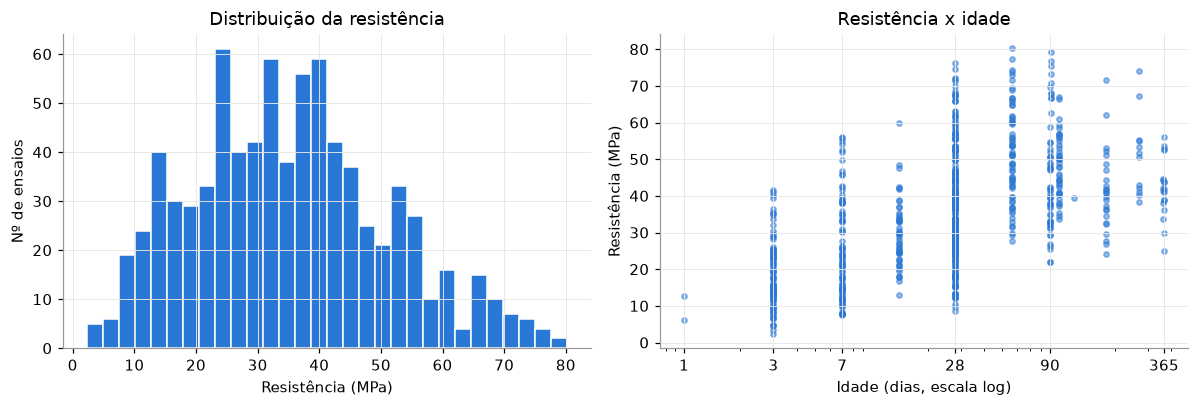

{1: 2, 3: 99, 7: 94, 14: 51, 28: 335, 56: 66, 90: 45, 91: 10, 100: 41, 120: 1, 180: 25, 270: 12, 360: 6, 365: 13}


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df[ALVO], bins=30, color=AZUL, edgecolor="white", linewidth=1)
ax[0].set(title="Distribuição da resistência", xlabel="Resistência (MPa)", ylabel="Nº de ensaios")
ax[1].scatter(df["idade"], df[ALVO], s=12, alpha=0.5, color=AZUL)
ax[1].set_xscale("log")
ax[1].set_xticks([1, 3, 7, 28, 90, 365]); ax[1].set_xticklabels([1, 3, 7, 28, 90, 365])
ax[1].set(title="Resistência x idade", xlabel="Idade (dias, escala log)", ylabel="Resistência (MPa)")
plt.tight_layout(); plt.savefig(FIG / "01_distribuicao_e_idade.png", bbox_inches="tight"); plt.show()
print(df["idade"].value_counts().sort_index().to_dict())

- A resistência vai de 2,33 a 80,20 MPa, com média de 35,20 MPa no treino.
- A **idade** tem efeito forte e **não linear**: o concreto ganha resistência rápido nas primeiras semanas e
  depois estabiliza. Por isso vamos usar também o **logaritmo da idade**.
- A idade só assume 14 valores, e 28 dias concentra ~40% dos ensaios.

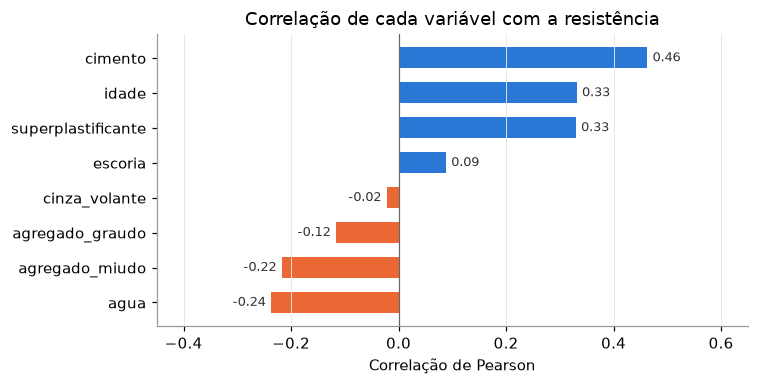

In [5]:
corr = df.corr()[ALVO].drop(ALVO).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(corr.index, corr.values, color=[LARANJA if v < 0 else AZUL for v in corr.values], height=0.6)
ax.axvline(0, color="#666666", linewidth=0.8)
ax.set(title="Correlação de cada variável com a resistência", xlabel="Correlação de Pearson")
for i, v in enumerate(corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color="#333333")
ax.set_xlim(-0.45, 0.65); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "02_correlacoes.png", bbox_inches="tight"); plt.show()

Nenhuma variável sozinha explica bem a resistência (maior correlação ≈ 0,5, do cimento). O comportamento depende da
**combinação** dos ingredientes. Um exemplo clássico da engenharia é a **lei de Abrams**: o que importa não é a quantidade
de água ou de cimento isoladamente, e sim a **relação água/cimento**.

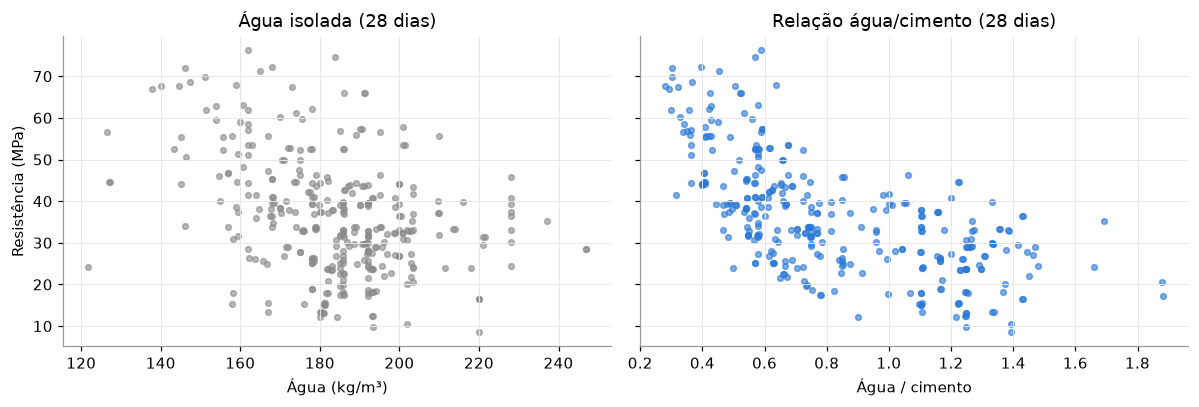

Correlação com a resistência aos 28 dias:
água               -0.37
água/cimento       -0.65
água/aglomerante   -0.76
dtype: float64


In [6]:
X_at = adicionar_atributos(df[ENTRADAS])
d28 = df["idade"] == 28
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax[0].scatter(df.loc[d28, "agua"], df.loc[d28, ALVO], s=14, alpha=0.6, color=CINZA)
ax[0].set(title="Água isolada (28 dias)", xlabel="Água (kg/m³)", ylabel="Resistência (MPa)")
ax[1].scatter(X_at.loc[d28, "relacao_agua_cimento"], df.loc[d28, ALVO], s=14, alpha=0.6, color=AZUL)
ax[1].set(title="Relação água/cimento (28 dias)", xlabel="Água / cimento")
plt.tight_layout(); plt.savefig(FIG / "03_relacao_agua_cimento.png", bbox_inches="tight"); plt.show()
print("Correlação com a resistência aos 28 dias:")
print(pd.Series({"água": df.loc[d28, "agua"].corr(df.loc[d28, ALVO]),
                 "água/cimento": X_at.loc[d28, "relacao_agua_cimento"].corr(df.loc[d28, ALVO]),
                 "água/aglomerante": X_at.loc[d28, "relacao_agua_aglomerante"].corr(df.loc[d28, ALVO])}).round(2))

A relação água/cimento teve maior correlação em valor absoluto com a resistência aos 28 dias do que a água isolada no treino.

### Tratamentos realizados (e por quê)

| Tratamento | Justificativa |
|---|---|
| Remoção de 25 duplicatas | Evitar que ensaios repetidos recebam peso extra |
| Zeros mantidos | Zero = aditivo não usado (informação real, não ausência) |
| Valores extremos mantidos | São ensaios reais de laboratório dentro de faixas fisicamente plausíveis |
| Novo atributo: relação água/cimento | Relação esperada entre proporção de água e resistência (lei de Abrams) |
| Novo atributo: relação água/aglomerante | Escória e cinza volante também atuam como aglomerantes |
| Novo atributo: log(idade) | Ganho de resistência rápido no início e lento depois |
| Padronização (StandardScaler) | Só nos modelos lineares; árvores não precisam |

A criação de atributos e a padronização ficam dentro dos pipelines dos modelos que as utilizam. A remoção de duplicatas ocorre antes da divisão.

## 4. Estratégia de avaliação

Uma divisão aleatória por linhas pode incluir um traço aos 28 dias no treino e o mesmo traço aos 56 dias na avaliação. Isso tende a reduzir o erro medido para o cenário de misturas inéditas.

O uso real é prever a resistência de uma **mistura nova**, então:

- **Teste final (cerca de 20% dos traços)** separado **por traço** (`GroupShuffleSplit`): nenhuma mistura do teste aparece no treino.
- **Validação cruzada de 5 folds por traço** (`GroupKFold`) no treino, para comparar modelos e escolher o melhor.
- Para mostrar o efeito, também rodamos a validação cruzada **aleatória** e comparamos.

**Métricas:**
- **MAE** (erro absoluto médio, em MPa): a mais fácil de interpretar ("erramos em média X MPa").
- **RMSE**: pune mais os erros grandes.
- **R²**: quanto da variação da resistência o modelo explica.

## 5. Modelagem

Comparamos do mais simples ao mais complexo:

1. **Baseline**: sempre prevê a média (referência mínima a ser batida).
2. **Regressão linear** com as 8 variáveis originais.
3. **Regressão linear + atributos** de engenharia (água/cimento, água/aglomerante, log da idade).
4. **Random Forest**: conjunto de árvores; capta não linearidades e interações.
5. **Gradient Boosting**: árvores treinadas em sequência, cada uma corrigindo os erros da anterior.

O código está em `src/modelos.py` e `src/treinar.py`.

In [7]:
from src.treinar import main as treinar
tabela, previsoes, importancia = treinar()

1005 amostras (após remover duplicatas) | 427 traços distintos
Treino: 800 | Teste: 205 (traços do teste nunca aparecem no treino)

Baseline (média)               MAE 12.85 ± 0.94 MPa | R² -0.013 | (CV aleatória: MAE 12.88)
Regressão linear               MAE  8.24 ± 0.61 MPa | R² 0.564 | (CV aleatória: MAE 8.26)
Regressão linear + atributos   MAE  5.58 ± 0.39 MPa | R² 0.795 | (CV aleatória: MAE 5.45)


Random Forest                  MAE  4.12 ± 0.76 MPa | R² 0.865 | (CV aleatória: MAE 3.53)


Gradient Boosting              MAE  3.76 ± 0.53 MPa | R² 0.886 | (CV aleatória: MAE 2.65)

Melhor modelo na validação cruzada: Gradient Boosting


Teste: {'MAE': 3.48, 'RMSE': 5.254, 'R2': 0.913}

MAE por faixa de idade:
               n   MAE
faixa_idade          
1-7 dias     58  3.05
8-28 dias    95  3.52
29-90 dias   29  3.86
91-365 dias  23  3.89



Intervalo 80%: previsão ± 5.8 MPa | cobertura no teste = 81.0%



Modelo salvo em models/modelo.joblib


In [8]:
cols = ["modelo", "cv_MAE", "cv_MAE_dp", "cv_RMSE", "cv_R2", "cv_aleatorio_MAE", "teste_MAE", "teste_RMSE", "teste_R2"]
tabela[cols].set_index("modelo").round(2)

,cv_MAE,cv_MAE_dp,cv_RMSE,cv_R2,cv_aleatorio_MAE,teste_MAE,teste_RMSE,teste_R2
modelo,,,,,,,,
Baseline (média),12.85,0.94,15.85,-0.01,12.88,14.40,17.81,-0.00
Regressão linear,8.24,0.61,10.33,0.56,8.26,8.48,10.72,0.64
Regressão linear + atributos,5.58,0.39,7.06,0.80,5.45,5.57,7.34,0.83
Random Forest,4.12,0.76,5.74,0.86,3.53,3.99,5.70,0.90
Gradient Boosting,3.76,0.53,5.26,0.89,2.65,3.48,5.25,0.91


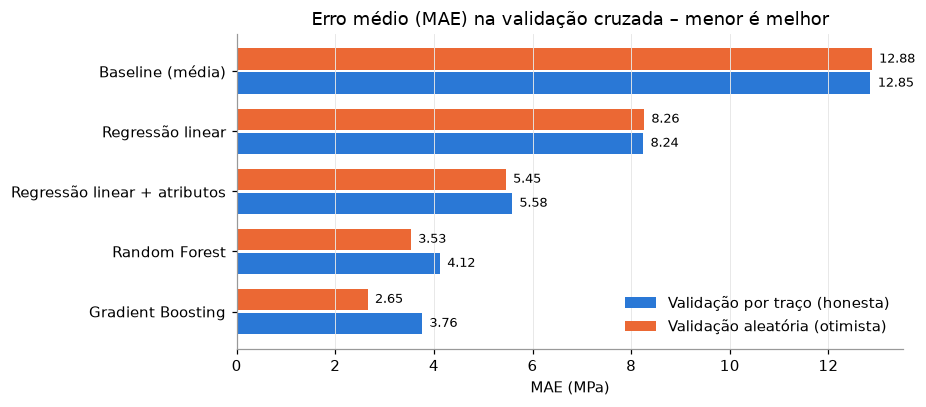

In [9]:
t = tabela.set_index("modelo")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = np.arange(len(t))
ax.barh(y + 0.2, t["cv_MAE"], height=0.36, color=AZUL, label="Validação por traço (honesta)")
ax.barh(y - 0.2, t["cv_aleatorio_MAE"], height=0.36, color=LARANJA, label="Validação aleatória (otimista)")
ax.set_yticks(y); ax.set_yticklabels(t.index); ax.invert_yaxis()
for i, (a, b) in enumerate(zip(t["cv_MAE"], t["cv_aleatorio_MAE"])):
    ax.text(a + 0.15, i + 0.2, f"{a:.2f}", va="center", fontsize=8.5)
    ax.text(b + 0.15, i - 0.2, f"{b:.2f}", va="center", fontsize=8.5)
ax.set(title="Erro médio (MAE) na validação cruzada – menor é melhor", xlabel="MAE (MPa)")
ax.legend(loc="lower right", frameon=False); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "04_comparacao_modelos.png", bbox_inches="tight"); plt.show()

### Leitura dos resultados

- **Todos os modelos batem a baseline** (MAE ~12,9 MPa).
- Só criar os atributos de engenharia já reduz o erro da regressão linear de ~8,2 para ~5,6 MPa,
  sem mudar de algoritmo. Conhecimento do domínio ajuda muito.
- Os modelos de árvores captam as interações restantes. O **Gradient Boosting** foi o melhor na validação por traço
  e foi o escolhido.
- **Efeito da divisão:** o Gradient Boosting obteve MAE de 2,65 MPa na validação aleatória e 3,76 MPa na validação por traço. São estimativas para protocolos diferentes.

## 6. Avaliação no conjunto de teste

A escolha do modelo usou o MAE da validação por traço. A tabela de teste compara os modelos depois dessa escolha.

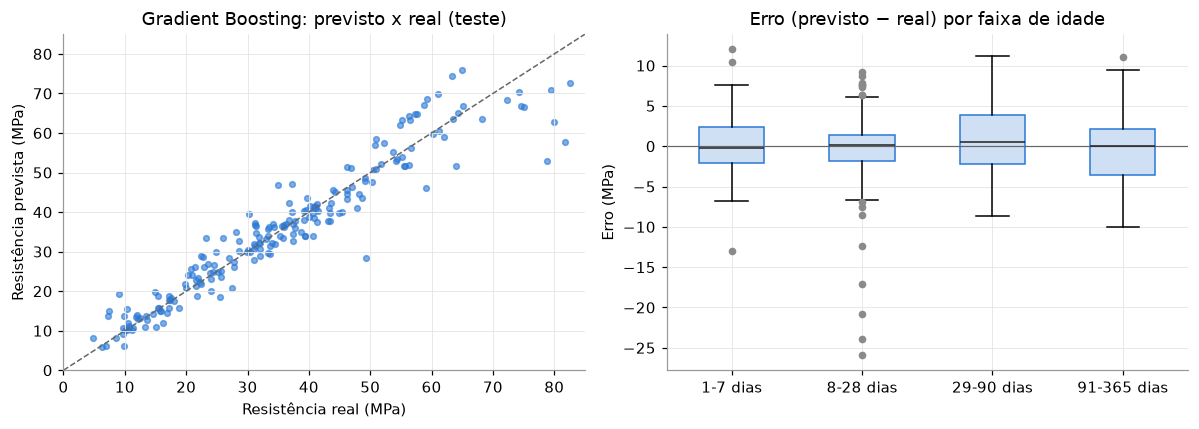

Teste: MAE = 3.48 MPa | RMSE = 5.25 MPa | R² = 0.913


In [10]:
melhor = tabela.loc[tabela["cv_MAE"].idxmin(), "modelo"]
p, r = previsoes[melhor], previsoes["real"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(r, p, s=14, alpha=0.6, color=AZUL)
lim = [0, 85]
ax[0].plot(lim, lim, color="#666666", linewidth=1, linestyle="--")
ax[0].set(xlim=lim, ylim=lim, title=f"{melhor}: previsto x real (teste)",
          xlabel="Resistência real (MPa)", ylabel="Resistência prevista (MPa)")
ordem = ["1-7 dias", "8-28 dias", "29-90 dias", "91-365 dias"]
dados = [previsoes.loc[previsoes["faixa_idade"] == f, "erro"] for f in ordem]
bp = ax[1].boxplot(dados, tick_labels=ordem, patch_artist=True, widths=0.5,
                   medianprops=dict(color="#222222"), flierprops=dict(markersize=4, markerfacecolor=CINZA, markeredgecolor=CINZA))
for b in bp["boxes"]:
    b.set(facecolor="#cfe0f5", edgecolor=AZUL)
ax[1].axhline(0, color="#666666", linewidth=0.8)
ax[1].set(title="Erro (previsto − real) por faixa de idade", ylabel="Erro (MPa)")
plt.tight_layout(); plt.savefig(FIG / "05_teste_previsto_real.png", bbox_inches="tight"); plt.show()
m = tabela.set_index("modelo").loc[melhor]
print(f"Teste: MAE = {m.teste_MAE:.2f} MPa | RMSE = {m.teste_RMSE:.2f} MPa | R² = {m.teste_R2:.3f}")

### Onde o modelo mais erra

In [11]:
piores = previsoes.assign(abs_erro=previsoes["erro"].abs()).nlargest(8, "abs_erro")
piores[["real", melhor, "erro", "idade"]].round(1)

,real,Gradient Boosting,erro,idade
90,78.8,52.9,-25.9,28
88,81.8,57.8,-23.9,28
93,49.2,28.4,-20.8,28
0,80.0,62.9,-17.1,28
20,59.1,46.1,-13.0,7
89,64.0,51.6,-12.4,28
17,34.9,46.9,12.0,7
28,63.4,74.5,11.1,56


In [12]:
erro_rel = (previsoes["erro"].abs() / previsoes["real"])
print(f"Erro relativo mediano: {erro_rel.median():.1%}")
print(f"Previsões com erro menor que 5 MPa: {(previsoes['erro'].abs() < 5).mean():.1%}")
print(f"Erro médio (viés): {previsoes['erro'].mean():+.2f} MPa")

Erro relativo mediano: 7.2%
Previsões com erro menor que 5 MPa: 75.1%
Erro médio (viés): -0.04 MPa


In [13]:
faixa = pd.cut(previsoes["real"], [0, 20, 40, 60, 90], labels=["até 20", "20-40", "40-60", "acima de 60"])
(previsoes.assign(abs_erro=previsoes["erro"].abs(), faixa_MPa=faixa)
 .groupby("faixa_MPa", observed=True)
 .agg(n=("abs_erro", "size"), MAE=("abs_erro", "mean"), vies_medio=("erro", "mean")).round(2))

,n,MAE,vies_medio
faixa_MPa,,,
até 20,45,1.99,0.70
20-40,84,2.87,0.97
40-60,56,3.91,-0.41
acima de 60,20,8.21,-4.87


Nos 20 ensaios de teste acima de 60 MPa, o MAE foi de **8,21 MPa** e a previsão ficou, em média, **4,87 MPa abaixo** da medição. Nas demais faixas, o MAE foi de 1,99 a 3,91 MPa.

## 7. O que o modelo aprendeu

Importância por permutação: embaralhamos uma variável de cada vez no teste e medimos quanto o erro piora.
Quanto mais piora, mais o modelo depende daquela variável.

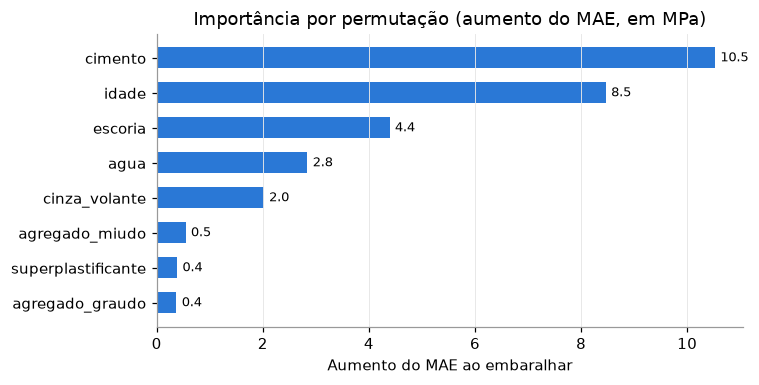

In [14]:
imp = importancia.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(imp.index, imp.values, color=AZUL, height=0.6)
for i, v in enumerate(imp.values):
    ax.text(v + 0.1, i, f"{v:.1f}", va="center", fontsize=8.5)
ax.set(title="Importância por permutação (aumento do MAE, em MPa)", xlabel="Aumento do MAE ao embaralhar")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "06_importancia.png", bbox_inches="tight"); plt.show()

O **cimento** e a **idade** dominam, seguidos da **escória** (que também age como aglomerante) e da **água**.
Essa medida indica quanto o modelo depende dessas variáveis nos dados avaliados.

## 8. Incerteza da previsão

O app mostra uma **faixa empírica**. A margem é o percentil 80 dos erros absolutos fora de cada fold na validação por traço. Com o modelo da avaliação, a faixa cobriu 81% das medições de teste. Após a avaliação, o modelo da demonstração foi ajustado com todos os dados. A cobertura de 81% descreve o teste anterior a esse ajuste.

In [15]:
import json
with (RAIZ / "reports" / "metricas.json").open(encoding="utf-8") as arquivo:
    print(json.dumps(json.load(arquivo)["intervalo_80"], indent=2))

{
  "margem_MPa": 5.797630307261892,
  "cobertura_teste": 0.8097560975609757
}


## 9. Demonstração de uso

Uma nova entrada produz um resultado compreensível. A mesma função é usada pelo app Streamlit (`streamlit run app.py`).

In [16]:
from src.prever import prever

traço_comum = dict(cimento=300, escoria=0, cinza_volante=0, agua=185, superplastificante=0,
                   agregado_graudo=1000, agregado_miudo=800)
for idade in [7, 28, 90]:
    r = prever(**traço_comum, idade=idade)
    print(f"Traço comum aos {idade:>2} dias: {r['resistencia_MPa']} MPa  (faixa empírica: {r['intervalo_80'][0]}–{r['intervalo_80'][1]} MPa)")

r = prever(**{**traço_comum, "agua": 150, "superplastificante": 10}, idade=28)
print(f"Menos água + superplastificante, 28 dias: {r['resistencia_MPa']} MPa")

r = prever(**{**traço_comum, "cimento": 800}, idade=28)
print("\nEntrada fora da faixa:", r["resistencia_MPa"], "MPa", r["avisos"])

Traço comum aos  7 dias: 16.4 MPa  (faixa empírica: 10.6–22.2 MPa)
Traço comum aos 28 dias: 27.9 MPa  (faixa empírica: 22.1–33.7 MPa)
Traço comum aos 90 dias: 34.0 MPa  (faixa empírica: 28.2–39.8 MPa)
Menos água + superplastificante, 28 dias: 35.9 MPa

Entrada fora da faixa: 74.2 MPa ['cimento = 800 está fora da faixa vista no treino (102 a 540); a previsão pode não ser confiável.']


Para a composição do exemplo, a previsão aumenta de 7 para 28 e 90 dias. O segundo exemplo muda a água e o superplastificante juntos. A função e o CLI avisam quando um valor está fora da faixa observada.

## 10. Conclusões, erros e limitações

**Conclusões**
- O Gradient Boosting prevê a resistência de **misturas nunca vistas** com erro médio de ~3,5 MPa e R² ≈ 0,91 no teste,
  contra 14,4 MPa da baseline no mesmo teste.
- Atributos baseados em engenharia (relação água/cimento) foram o maior ganho isolado nos modelos lineares.
- Avaliar **por traço** foi essencial: a validação aleatória apresentou MAE cerca de 29% menor neste experimento.

**Erros e limitações**
- Os maiores erros estão nos **concretos de alta resistência (> 60 MPa)**: o modelo os subestima em 4,87 MPa em média nos 20 exemplos de teste dessa faixa.
- O dataset tem só ~1.000 ensaios de laboratório. O uso com materiais locais exige uma avaliação adicional.
- Não há informações como tipo de cimento, tipo de brita, cura e temperatura, que também afetam a resistência.
- Fora das faixas do treino (ex.: cimento > 540 kg/m³) as previsões são mais incertas. A função e o CLI sinalizam extrapolação.
- O modelo **não substitui o ensaio** de rompimento; serve para triagem e comparação de traços.

**Próximos passos**
- Ajuste de hiperparâmetros com busca em grade por traço; testar XGBoost/LightGBM.
- Usar SHAP para explicar previsões individuais.
- Coletar dados de uma concreteira local para validar o modelo na realidade brasileira.